

# Table of Contents

**Phase 1: Data Preparation and Metrics Definition**
- 1.1 Preprocessing and Data Cleaning
- 1.2 Definition of Key Metrics
- 1.3 Network Construction and Representation

**Phase 2: Outbreak Detection and Analysis**  
- 2.1 Community Exploration and Structure Analysis	
- 2.2 Outbreak Identification and Characterization

**Phase 3: Propagation and Diffusion Analysis**  
- 3.1 Cascade Tracing and Flow Dynamics
- 3.2 Immunity and Containment Effects

**Phase 4: Lifecycle and Evolution Study**  
- 4.1 Detection of Cycles and Key Events
- 4.2 Evolutionary Tracking Over Time

**Phase 5: Validation and Synthesis of Results**  
- 5.1 Cross-Validation and Robustness Checks
- 5.2 Final Interpretation and Conclusions


### **Install Requirements**

In [1]:
%pip install -r pip_requirements.txt

Note: you may need to restart the kernel to use updated packages.


### **Imports**

*Note that you need a 'Data' folder containing the 4 datasets defined in the README. This folder should be placed at the same level as src and tests directories.*

In [2]:
# Jupyter Notebook Utils
%matplotlib inline
%load_ext autoreload
%autoreload 2

# Python Libraries
import pandas as pd
import numpy as np
import matplotlib.dates as mdates
from datetime import date
import matplotlib.pyplot as plt
import seaborn as sns
import math
from scipy import stats
from statsmodels.stats import diagnostic
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Own modules
from src import *


Computing SOURCE (aggressor) features...


# Project pipeline




---
# Phase 1: Data Preparation

## 1.1 Preprocessing & Cleaning


### Data Quality Checks, Unification & Standardization

We import and preprocess data through the following steps:

1. Import TSV files and expand PROPERTIES column into 86 features
2. Merge together both title and body datasets in a unified dataset, with `TYPE` to retain information of source.
3. Standardize subreddit names (lowercase, trim whitespace)
4. Convert timestamps to datetime and chronologically reorder the combined dataset (temporal integrity was altered by merging)
5. Format embeddings datasets (one subreddit per row, one column for each embedding dimension)
6. Check data quality (missing values, timestamp parsing)
7. Check for duplicates and document dataset overlap

The steps are performed using functions defined in `init_data.py`.

In [3]:
# Data quality and duplicates check
check_quality(interactions_df)
check_quality(embeddings_subreddits_df)
check_quality(embeddings_users_df)


=== QUALITY REPORT ===
Shape: (858488, 92)

Missing values:
 SOURCE_SUBREDDIT                          0
LIWC_COGMECH                              0
LIWC_PERCEPT                              0
LIWC_EXCL                                 0
LIWC_INCL                                 0
                                         ..
LIWC_PPRON                                0
LIWC_PRONOUN                              0
LIWC_FUNCT                                0
COMPOUND_SENTIMENT_CALCULATED_BY_VADER    0
TYPE                                      0
Length: 92, dtype: int64

Duplicate rows: 0

=== QUALITY REPORT ===
Shape: (51278, 301)

Missing values:
 SUBREDDIT    0
emb_206      0
emb_204      0
emb_203      0
emb_202      0
            ..
emb_99       0
emb_98       0
emb_97       0
emb_96       0
emb_299      0
Length: 301, dtype: int64

Duplicate rows: 0

=== QUALITY REPORT ===
Shape: (118381, 301)

Missing values:
 USER       0
emb_206    0
emb_204    0
emb_203    0
emb_202    0
          

In [4]:
# DataFrame after STEP 1 
interactions_df.head()

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,...,LIWC_LEISURE,LIWC_HOME,LIWC_MONEY,LIWC_RELIG,LIWC_DEATH,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER,TYPE
0,agitation,changemyview,1u5cj7s,2013-12-31 16:20:20,1,102.0,91.0,0.843137,0.000000,0.088235,...,0.000000,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title
1,rddtgaming,rddtrust,1u4pzzs,2013-12-31 16:39:18,1,25.0,23.0,0.760000,0.000000,0.440000,...,0.000000,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title
2,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,345.0,298.0,0.756522,0.017391,0.086957,...,0.034483,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,body
3,examplesofevil,pics,1u5lhas,2013-12-31 16:40:29,1,96.0,83.0,0.833333,0.000000,0.062500,...,0.000000,0.0,0.0,0.0,0.0625,0.0,0.0,0.000000,0.000000,title
4,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,1124.0,949.0,0.772242,0.001779,0.057829,...,0.020833,0.0,0.0,0.0,0.0000,0.0,0.0,0.020833,0.005208,body


## 1.2 Definition of Key Toxicity Metrics



**Aggregation Levels:**
All metrics computed at multiple scopes:
- Subreddit level (aggregated over time windows)
- Subreddit-pair level (source → target relationships)
- Community cluster level (aggregated within detected communities)

### 1.2.1 Toxicity score $\in [-1, 1]$

**Definition of toxicity**

Our first fundamental preliminary step is to calculate a reliable and accurate metric of toxicity of each subreddit's post.

We define toxicity as patterns of communication or behavior that create a hostile, disrespectful, or harmful environment for participants. This can include insults, harassment, hate speech, excessive negativity, or attempts to provoke conflict. Toxicity reduces constructive discussion, discourages participation, and can damage the overall health and cohesion of the community.

This definition aligns with standard computational social science literature, where toxicity requires both negative emotional valence, and linguistic markers of aggression or harmful intent. Reddit, being a large, anonymous, and heterogeneous platform, often exhibits these patterns, making it an appropriate setting for a linguistic toxicity metric.

**The 86 textual properties we have at hand**

Our dataset includes 86 textual properties covering structural, lexical, emotional, and LIWC-derived indicators. While these features were not originally designed specifically for toxicity detection, prior research shows that they collectively capture many linguistic correlates of antagonistic or degrading speech. Let's understand what they actually represent:

***Properties 1 to 18*** capture surface-level linguistic and structures of the text. They measure the basic composition and readability of a message, including its length, complexity, and word or sentence structure. They include metrics such as character and word counts, fractions of different character types (letters, digits, punctuation, etc.), sentence length averages, and readability scores. Together, they provide a quantitative snapshot of how the text is written rather than what it expresses.

***Properties 19 to 21*** represent sentiment analysis metrics, derived using the VADER (Valence Aware Dictionary and sEntiment Reasoner) model. They aim to measure the emotional polarity of the text. It includes the Positive Sentiment, Negative Sentiment and Compound Sentiment. These features reflect the emotional valence of the language used.

***Properties 22 to 86*** are purely lexicon-based ratios, derived using a text analyis tool called Linguistic Inquiry and Word Count (LIWC). Each LIWC represent the proportion of words in a text that belong to a certain lexicon: LIWC_X = (nb words in lexicon X) / (total nb words). While useful to see the presence of a certain vocubulary in a post, they remain purely lexical and doesn't treat emotion or sentiment in any way.

In summary, while each property individually has limitations, together they provide a rich representation of linguistic features relevant to toxic communication.

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">
<code>TOXICITY_SCORE</code>: continuous metric that measures the toxicity intensity in a subreddit post, using the 86 existing properties 
</div>

(Function also implemented in `compute_toxicity_score.py` in `utils` module.)

**Properties that are interesting for capturing toxicity**

| Dimension | Description | Example of properties to use |
|------------|--------------|------------------|
| **Emotional intensity** | Measures strength of negative emotion | `Neg_Vader`, `LIWC_Negemo`, `LIWC_Anger`, `LIWC_Anx`... |
| **Aggressive** | Captures hostile or taboo language | `LIWC_Swear`, `LIWC_Sexual`, `LIWC_Death`, `LIWC_Relig`... |
| **Targeting** | Focus on others (potential hostility toward people/groups) | `LIWC_You`, `LIWC_Humans`, `LIWC_Social`... |
| **Not cognitive** | Opposite of reasoned or analytical tone | `LIWC_Insight`, `LIWC_Cause`... |
| **Violent and short** | Style indicators of impulsive or aggressive speech | `Number of UPPERCASE words`, `Readability index`... 

However, above all these textual properties, we also consider true **negativity** of a post to be a **necessary** component for it to be toxic.


**Why is the VADER score not enough for measuring negativity?**

The fundamental problem is that none of the 86 properties provides a reliable measure of **emotional negativity** in a post.

While the VADER scores seemed promising (optimized for social media texts and posts), they mainly work like a LIWC score and calculate emotion of the **language** that was used (like an advanced lexical repertory of words that are conventionally considered negative or harmful on social platforms).

This cannot be considered an accurate measure of negativity in our context. For example, some shortfalls of lexical metrics include:

- Sarcasm, irony, and context
  - “Stupid guy” in a link targeting a funny video of a guy slipping 
  - “Stupid guy” in a link targeting a video of Trump’s speech  

- Cultural difference in language
  - Some communities are (by culture) founded on “offensive” language without being toxic.
  - For example, a *CallOfDuty* subreddit will frequently mention terms like "kill" or “assassination”. These words are not toxic in that community, but could be considered so in other subreddits (ones not related to war or gaming).

Because toxicity in our definition must reflect true negative intent, not just negative words, lexical sentiment proves insufficient.

**Good news: `LINK_SENTIMENT` solves this problem.**

`LINK_SENTIMENT` is derived using a supervised sentiment classifier trained on manually labeled Reddit data. When labeling, the authors have taken into account their human judgement of context, irony etc. in addition of a purely lexical analysis. So `LINK_SENTIMENT` is designed specifically for inter-subreddit interactions and is our most reliable (categorical) measure for pure negativity.

**Identifying Linguistic Properties Associated With Negativity**

To understand which properties meaningfully contribute to negative interactions, we compare normalized mean property values between positive and negative links. The idea behind this procedure is that:

- Comparing group means detects systematic differences in linguistic patterns
- Normalization accounts for differing scales and distributions across features
- Toxicity-related linguistic features are expected to cluster more strongly in negative posts
- Identifying features more common in negative interactions ensures alignment with our conceptual model (toxicity requires negativity)

Although this procedure does not infer causality and therefore doesn't replace the qualitative choice of toxicity components, it strongly supports it by ensuring that we later select variables that are consistent with the requirement of negativity in toxicity.

**Selecting the z-difference threshold**

We select a z-difference threshold of 0.25, which retains ~20 properties. Why is it justified?

- A difference of **0.25 standard deviations** corresponds to a small-to-moderate effect size. In textual and psychological data, small-to-moderate effects are often meaningful because language patterns are inherently noisy and multidimensional. A 0.25 cutoff ensures that **weak or negligible features are excluded**, while **features with clear group differences in positive vs negative sentiment are retained**. This balances strictness with comprehensiveness.

- As we explained above in our definition of toxicity, it cannot be captured by a single marker but arises from a constellation of linguistic behaviors.Well-validated toxicity models (Google Perspective API, Jigsaw toxicity challenges...) incorporate dozens of features, not just a few. On the other side, if the metric relied on too many features, it would risk misinterpreting domain-specific vocabulary as toxic and producing high-variance estimates for minority communities. Using ~20 features distributes the metric across a reasonably braod linguistic base, improving stability and most importantly cross-subreddit generalizability.

- 20 features is consistent with dimensionality in psycholinguistic instruments. Psycholinguistic tools like Empath (200+ categories) or Biber’s Dimensions of Register Variation (50+ linguistic dimensions) show that meaningful linguistic traits require between 10 and 30 variables to capture reliably.

To summarize these argumennts, retaining **20 properties** maximizes informational coverage, ensures robustness across heterogeneous subreddits, matches standard dimensional expectations from psycholinguistics, and corresponds to a statistically meaningful effect-size cutoff. The threshold of **0.25** therefore strikes the optimal balance between inclusiveness and discriminative power.

In [5]:
threshold_zdiff = 0.25
avg_z_diffs = evaluate_props_norm_diffs(interactions_df, threshold_zdiff)

**Combining Features Into the Toxicity Metric**

Based on the conceptual qualitative choice of what defines toxicity and the empirical negativity analysis above, we select a subset of properties to constitute our toxicity metric. These properties already exist in ratio form (0–1), ensuring comparability.

**Weighted Average Approach**

We define `TOXICITY_SCORE` as a weighted linear combination of the selected properties. A linear model is appropriate because it balances interpretability (and will allow immediate examination of feature contributions) with simple comparison across subreddits. It also supports later scaling, standardization, and model-based refinements. Weights are based on informed judgments from literature on aggressive discourse (e.g., strong weight on anger and swearing; negative weight on cognitive complexity features like insight or cause).


**Weights are normalized by the sum of absolute values**. This choice preserves relative influence of features and rescales the score into a bounded and interpretable range. Il also ensures no single feature arbitrarily dominates due to coefficient magnitude. This normalization is a standard approach for interpretability when working with heterogeneous features and manually chosen weights.

Mathematically, `TOXICITY_SCORE` will therefore range from -1 to 1.






In [6]:
tox_props = pd.DataFrame([
    [-3, "FRACTION_OF_DIGITS"],
    [1, "FRACTION_OF_STOPWORDS"],
    [5, "NEGATIVE_SENTIMENT_CALCULATED_BY_VADER"],
    [-5, "LIWC_CAUSE"],
    [-5, "LIWC_INSIGHT"],
    [5, "LIWC_SWEAR"],
    [1, "LIWC_SOCIAL"],
    [1, "LIWC_HUMANS"],
    [1, "LIWC_NEGEMO"],
    [5, "LIWC_ANGER"],
    [1, "LIWC_SEXUAL"]
    ],
    columns = ["weight", "name"])

# Normalize weights
tox_props["weight (normd)"] = tox_props["weight"] / tox_props["weight"].abs().sum() 

interactions_df["TOXICITY_SCORE"] = (interactions_df[tox_props["name"].to_list()].values * tox_props["weight (normd)"].to_list()).sum(axis = 1)

In [7]:
plot_toxicity_camembert(tox_props)

Let's visualize our new metric's empirical distribution.

count    858488.000000
mean          0.016344
std           0.023457
min          -0.113636
25%           0.002127
50%           0.009925
75%           0.023687
max           0.416061
Name: TOXICITY_SCORE, dtype: float64


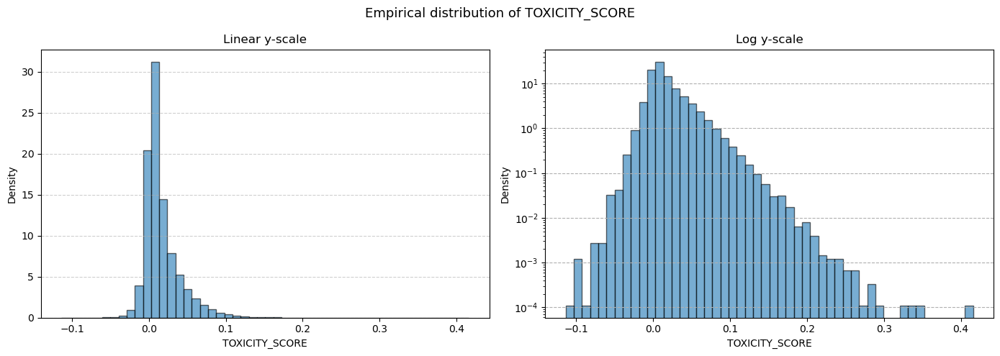

In [8]:
plot_empirical_distribution(interactions_df["TOXICITY_SCORE"], "TOXICITY_SCORE")

Theoretically, the score ranges from –1 to 1, but empirically falls within –0.1 to 0.4, reflecting real distributions in Reddit posts. Since the scale is later standardized, this restricted range is not problematic.

### 1.2.2 Toxicity binary classification $\in \{0, 1\}$

We now have a reliable, continuous measure of toxicity. But it's not necessarily easy to interpret directly... We would like to accompany this continuous metric with a binary classification: "Is this toxicity score value sufficiently high? In other words, is this message toxic?"

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">
<code>TOXICITY_CAT</code>: categorical metric that classifies posts as non-toxic (0) or toxic (1), after passing a threshold on <code>TOXICITY_SCORE</code>. 
</div>

**Selecting the binary toxicity classification threshold**

The threshod above which messages are flagged as toxic is the quantile-75 of the toxicity scores distribution. That is, **we mark as significantly toxic the top 25% messages with highest score**. What motivates our choice?

- Toxic behavior is statistically rare — and tail-based thresholds reflect this. Online toxicity is considered to be heavy-tailed in the sense that most posts are neutral, while toxic ones are relatively rare and concentrated at the upper end of the distribution. Selecting the **upper quartile (top 25%)** isolates the **long tail of intense language** but ensures coverage of sufficiently frequent abusive content.
Thus, the 75th percentile is a natural and theoretically grounded boundary.

- 75th percentile ensures class balance suitable for downstream modeling. Binary classification tasks require a **non-trivial positive class** to avoid degenerate models.  
   Cutting at:
   - 90% → positive class too small (5–10%), sparse, high variance  
   - 50% → positive class too large, not aligned with toxicity rarity  

- The 75th percentile is conceptually aligned with “significant toxicity”. By definition, we want to classify only **strongly toxic** posts as toxic.  
Choosing the **top quartile** is a reliable way to identify posts with unusually high use of aggressive markers and atypical linguistic patterns. This makes toxicity classification interpretable and consistent across subreddits.

75% quantile threshold: 0.02368686868687879


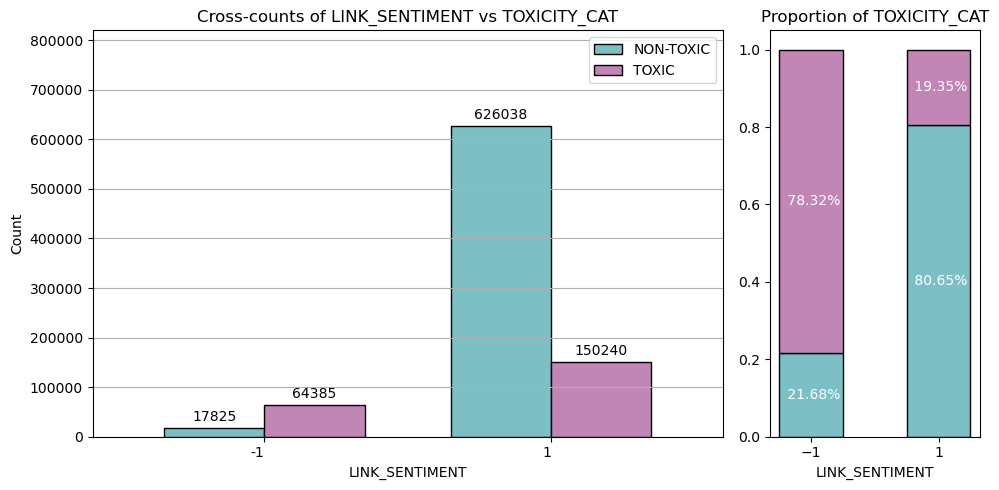

In [9]:
threshold_toxicity = interactions_df["TOXICITY_SCORE"].quantile(0.75)
print("75% quantile threshold:", threshold_toxicity)

interactions_df["TOXICITY_CAT"] = (interactions_df["TOXICITY_SCORE"] >= threshold_toxicity).astype(int)

cross_count_SENTIMENT_TOXICITY(interactions_df)

At first, it appears that the majority of toxic messages are actualy labeled positive, which is not desirable as we explicited that, in our context, toxicity only comes with negativity. 

However, looking at the **proportions** of toxicity in each sentiment class (right barplot), we see that around 78% of negative messages are labeled toxic, while only 19% of positive messages were. Negative messages are much more likely to be toxic (which makes sense based on the properties we retained to define toxicity).

In the next cell, we enforce the rule that only messages with negative sentiment (`LINK_SENTIMENT` = −1) can be classified as toxic (`TOXICITY_CAT` = 1). This decision is based on a conceptual definition of toxicity as hostile, harmful, or abusive discourse, which fundamentally requires a negative emotional valence. Although positive/neutral-sentiment messages may sometimes contain high levels of features like swearing or anger, classifying them as toxic would introduce significant false positives that do not align with the standard understanding of online harassment or abuse.

**Remark**

The continuous `TOXICITY_SCORE` is preserved even for the links that are ultimately filtered out by the sentiment check. This score serves as a crucial linguistic feature intensity metric, quantifying the sheer presence of aggressive or low-quality language features (e.g., swearing, anger, simplicity) independent of the link's overall "true" sentiment. By keeping the raw score, we retain valuable information for later analysis, such as comparing the distribution of strong language features across both toxic (negative sentiment) and non-toxic (positive sentiment) messages, which can reveal linguistic patterns related to intense discourse beyond just negative intent.

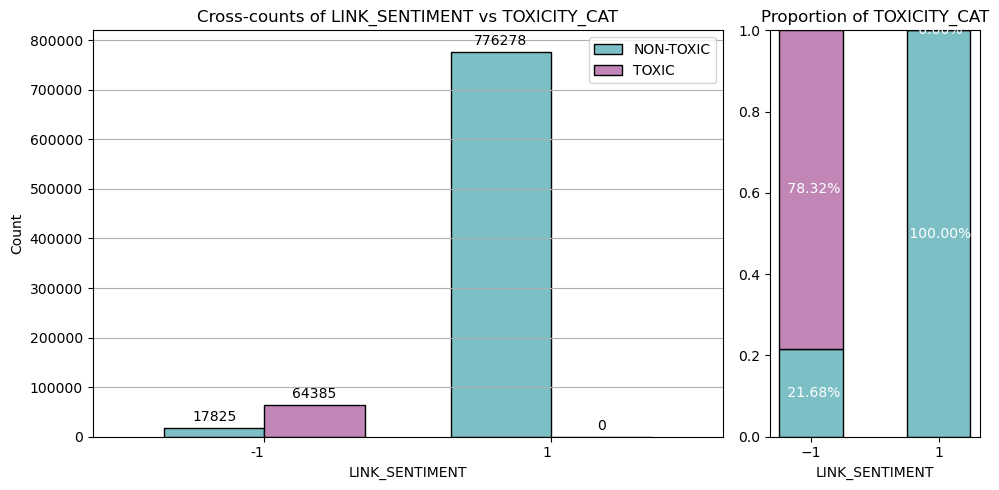

In [10]:
interactions_df["TOXICITY_CAT"] = ((interactions_df["TOXICITY_CAT"] == 1) & (interactions_df["LINK_SENTIMENT"] == -1)).astype(int)

# Sanity check (to verify elimination of false positives)
cross_count_SENTIMENT_TOXICITY(interactions_df)

Let's see how much toxic posts we detected over the entire period. The following plot aggregates over all subreddits and averages monthly, but acts as a quick sanity check to see if the count stays coherent over time.

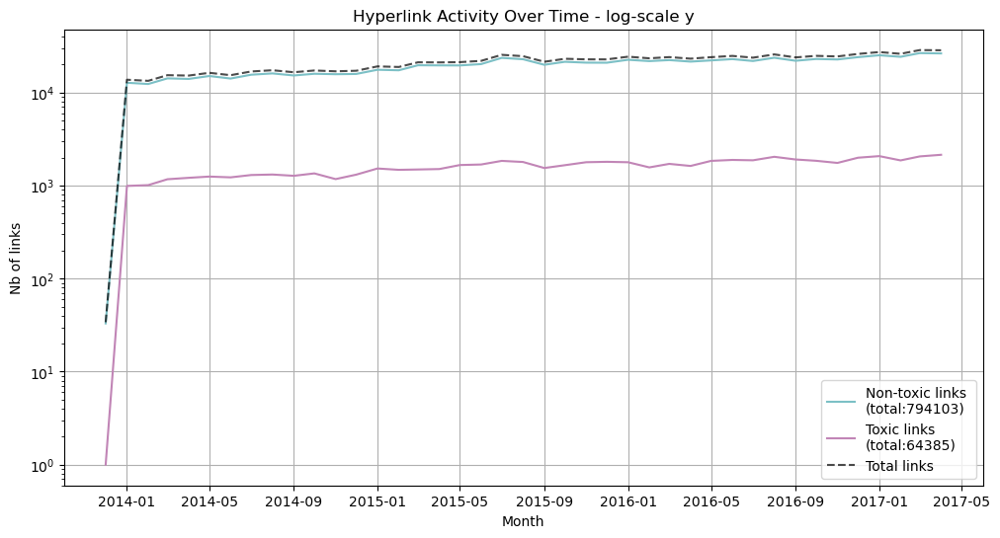

In [11]:
hyperlink_activity_over_time(interactions_df)

---
# Phase 2: Study of Propagation Types - Clustering

## Motivation

Understanding toxic behavior on Reddit requires more than just identifying which posts are toxic. Indeed, we need to understand the **temporal and behavioral patterns** that characterize different types of toxicity. Not all toxic subreddits behave the same way of acting and spreading through time .

Some communities may be **chronic aggressors** that consistently attack others over long periods, while others might be **episodic attackers** that have sudden bursts of toxic activity triggered by specific events. Similarly, some communities may act as **frequent victims** of incoming toxicity, while others engage in **reciprocal toxic exchanges** with specific adversaries. There may even be **dormant toxic communities** that have brief, intense periods of activity separated by long quiet intervals.

**The goal of this clustering analysis is to identify distinct temporal and behavioral patterns of toxicity** and not just sticking to simple binary classification (toxic vs. non-toxic). For this, we use a combination of:
- **Temporal features** (when and how often toxic events occur)
- **Role-aware features** (aggressor vs. victim behavior)  
- **Network features** (degree centrality, reciprocity)

we aim to classify subreddits into meaningful behavioral archetypes that reveal the **dynamics and rhythm** of toxic behavior over time.

<!-- This classification will help us:
1. **Understand toxicity propagation mechanisms**: Do certain behavioral patterns make communities more likely to spread toxicity?
2. **Identify intervention targets**: Should moderation efforts focus on chronic aggressors, episodic bursters, or vulnerable victims?
3. **Predict future toxic outbreaks**: Can we use these patterns to anticipate which communities are at risk of escalating toxic behavior? -->

This classification will help us:
1. **Characterize toxicity spread patterns**: How do different types of hate spread across Reddit? Which behavioral patterns are most common?
2. **Understand community roles and activity**: Are there more aggressors or victims? Can we identify hyperactive toxic members who drive most of the hostile interactions?
3. **Detect temporal dynamics**: Is there periodicity in toxic behavior? Do certain patterns follow predictable cycles or seasonal trends?


By capturing the multidimensional nature of toxic behavior not just its presence, but its frequency, intensity, timing, and directionality, we can develop a better understanding of how toxicity manifests and evolves across the Reddit ecosystem.

In [12]:
df, umap_available, hdbscan_available, reducer_name = preliminary_control(interactions_df)

## 2.1 Features used for Clustering

In order to be able to cluster subreddits based on their toxic behavior, we first need to define relevant features that capture different aspects of toxicity dynamics. We focus on three main dimensions: temporal features, role-aware features, and network features.

### 2.1.1 Role Aware Temporal Features: Source vs Target Behavior

##### Why Separate Aggressor and Victim Roles?

Understanding toxic behavior on Reddit requires distinguishing between **who is sending** and **who is receiving** toxic content. A subreddit's role in the toxicity network, whether as an aggressor, a victim, or both, fundamentally shapes its behavioral pattern and requires different features to capture accurately.

**The key idea with an example**: A subreddit that sends 100 toxic messages and receives 10 is behaving very differently from one that sends 10 and receives 100, even though their total toxic interaction count is the same. To cluster subreddits correctly, we need to capture these distinct roles separately.

##### Why This Matters for Clustering?

By computing temporal features separately for **source (aggressor)** and **target (victim)** roles, we can:

1. **Identify behavioral archetypes**: Some subreddits are predominantly aggressors (high outgoing toxicity), others are frequent victims (high incoming toxicity), and some engage in reciprocal toxic exchanges (high in both directions).

2. **Capture interaction dynamics**: Understanding who is giving and who is receiving toxic content reveals the directional flow of toxicity across the Reddit ecosystem. This is essential for understanding propagation mechanisms.

3. **Enable nuanced clustering**: Without role separation, we would lose critical information. A chronic aggressor and a frequent victim might have similar total toxic event counts, but their temporal patterns, motivations, and impacts on the community are completely different.

We therefore compute all temporal features twice, once for source (outgoing toxic interactions) and once for target (incoming toxic interactions), giving us a complete picture of each subreddit's toxic behavior profile.


#### Source (Aggressor) Temporal Features

- **`src_tox_count`**: Total number of toxic interactions sent by the subreddit over the entire period. This measures the overall volume of toxic aggression.

- **`src_active_span_days`**: The time span (in days) between the first and last toxic interaction sent. This captures how long the subreddit has been actively sending toxic content.

- **`src_median_gap_days`**: The median number of days between consecutive toxic interactions sent. This indicates the typical waiting time between toxic outbursts.

- **`src_gap_cv`**: The coefficient of variation (CV) of the gaps between toxic events. A low CV indicates regular, periodic toxic behavior, while a high CV suggests irregular, sporadic bursts.

- **`src_max_30d_count`**: The maximum number of toxic interactions sent within any 30-day window. This identifies the intensity of the subreddit's worst toxic period.

- **`src_event_rate`**: The average rate of toxic events sent (toxic count / active span). This normalizes activity by duration, distinguishing between sustained and brief toxic phases.

- **`src_pct_events_recent`**: The percentage of toxic events that occurred in the recent portion of the observation period. This helps identify whether toxicity is increasing, decreasing, or stable over time.

#### Target (Victim) Temporal Features

- **`tgt_tox_count`**: Total number of toxic interactions received by the subreddit. This measures the overall volume of incoming toxicity.

- **`tgt_active_span_days`**: The time span (in days) between the first and last toxic interaction received. This captures how long the subreddit has been a target of toxic behavior.

- **`tgt_median_gap_days`**: The median number of days between consecutive toxic interactions received. This indicates the typical frequency of incoming attacks.

- **`tgt_gap_cv`**: The coefficient of variation of the gaps between received toxic events. This distinguishes between subreddits that receive steady harassment versus those targeted in irregular bursts.

- **`tgt_pct_events_recent`**: The percentage of received toxic events that occurred in the recent portion of the observation period. This helps identify whether a subreddit is becoming a more frequent target over time.

#### Why These Features Matter?

These temporal features allow us to distinguish between different behavioral patterns, such as:
- **Chronic aggressors** (high count, long span, regular gaps) vs. **episodic attackers** (high count, short span, irregular gaps)
- **Sustained victims** (long span, regular incoming attacks) vs. **event-triggered targets** (short span, clustered attacks)
- **Escalating toxicity** (high % recent events) vs. **declining activity** (low % recent events)

In [13]:
# We build separate features for source (aggressor) and target (victim) roles
toxic_df = interactions_df[interactions_df["TOXICITY_CAT"] == 1].copy()
source_df, source_features = comp_source_features(toxic_df)

  SOURCE features computed for 6921 subreddits


In [14]:
target_df, target_features = comp_target_features(toxic_df)

  TARGET features computed for 5333 subreddits


### 2.1.2 Network Features

##### Why Network Structure Matters?

Beyond understanding when toxic behavior occurs (temporal features) and who is aggressor vs. victim (role-aware features), we need to understand the **network structure** of toxic interactions. Network features capture how subreddits are positioned and connected within the broader toxic interaction network, revealing patterns of isolation, centrality, and reciprocal relationships.

##### Network Metrics

- **`net_out_degree`**: The number of **distinct subreddits** that this subreddit has sent toxic messages to. This measures whether a subreddit targets a single adversary or spreads toxicity across many different communities. A high out-degree indicates a subreddit that engages in widespread toxic behavior.

- **`net_in_degree`**: The number of **distinct subreddits** that have sent toxic messages to this subreddit. This measures whether a subreddit is targeted by a single source or receives toxicity from many different communities. A high in-degree might indicate a controversial or polarizing subreddit.

- **`net_reciprocity`**: The proportion of toxic relationships that are **bidirectional** (subreddits that both send and receive toxic messages from each other). This captures **mutual toxic exchanges**. High reciprocity suggests active "toxic exchanges" rather than one-sided harassment.

##### Why Network Features Enable Better Clustering?

These features reveal fundamentally different behavioral patterns:

- **Isolated aggressors** (high out-degree, low in-degree, low reciprocity): Subreddits that attack many others but rarely receive toxicity back, potentially trolling or attacking communities.

- **Targeted victims** (low out-degree, high in-degree, low reciprocity): Subreddits that receive toxicity from many sources but don't retaliate, potentially controversial topics or vulnerable communities.

- **Adversarial communities** (balanced degrees, high reciprocity): Subreddits engaged in mutual toxic exchanges, potentially rival communities with ongoing conflicts, for example in sports with rival teams.

- **Toxic hubs** (high out-degree, high in-degree, moderate reciprocity): Central nodes in the toxic network that both spread and attract toxicity, potentially highly polarizing or contentious communities.

By combining network features with temporal and role-aware features, we capture the complete picture of how each subreddit participates in the toxic ecosystem.

In [15]:
out_degree, in_degree = compute_out_in_degree(source_df, target_df)

In [16]:
# We compute reciprocity for each subreddit
reciprocity = call_compute_reciprocity(source_df, target_df, toxic_df)

In [17]:
temporal_features = merge_all_features(source_features, target_features, out_degree, in_degree, reciprocity)


Total subreddits before filtering: 9752


/Users/cedriczanou/Desktop/MA3/ADA/ada-2025-project-adastra/src/utils/clustering_utils.py:424: FutureWarning:

Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0' has dtype incompatible with datetime64[ns], please explicitly cast to a compatible dtype first.



## 2.2 Clustering Preprocessing

### 2.2.1 Filtering Low-Activity Subreddits

Given that our dataset spans approximately 2.5 years (roughly 900 days), we need to carefully handle edge cases where subreddits have very little toxic activity. Including subreddits with only a handful of toxic interactions would introduce several problems:

1. **Statistical unreliability**: Temporal features like median gap days, coefficient of variation, and event rates become meaningless or highly unstable when computed from very few data points. For example, a subreddit with only 2-3 toxic events cannot provide a reliable measure of behavioral patterns.

2. **Feature computation issues**: Many of our features require multiple events to be meaningful:
   - Gap CV (coefficient of variation) needs multiple gaps to measure consistency
   - Median gap requires at least several events to be representatives

3. **Noise amplification**: Subreddits with minimal activity often have extreme or outlier feature values that don't represent true behavioral patterns but rather random fluctuations.

4. **Practical relevance**: A subreddit with only a few toxic interactions over 2.5 years is not exhibiting meaningful toxic behavior patterns worth clustering. It can be classified as non-toxic with occasional isolated incidents.

##### Justifying the Threshold of 10 Toxic Events

We set the minimum threshold at **10 toxic events** based on the following considerations:

- **Clustering quality**: Empirically, including subreddits with fewer than 10 events tends to create outlier clusters dominated by noise rather than revealing meaningful behavioral archetypes. 10 represents a reasonable balance between retaining enough data for robust clustering while excluding statistically unreliable cases.

In [18]:
temporal_features = filter_low_activity(temporal_features, min_toxic_events=10)

Subreddits after filtering (>= 10 total toxic events): 1364


### 2.2.2 NaN Handling

After computing temporal and network features, we perform a quick sanity check to handle any missing values (NaNs) that may have appeared during feature computation. This ensures our feature matrix is complete and ready for clustering algorithms, which typically cannot handle missing values. This step validates data integrity before proceeding to feature scaling and dimensionality reduction.

In [19]:
temporal_features = temporal_nan_handling(temporal_features)
temporal_features = other_nan_handling(temporal_features)

### 2.2.3 Feature Correlation, Multicolinearity Analysis and Feature Scaling

When clustering temporal toxicity patterns, we face three interconnected challenges that can seriously undermine our results. 

First, many of our features are inherently correlated: for instance, subreddits with high toxic event counts naturally tend to have longer activity spans, and network centrality measures often move together. This multicollinearity biases distance-based algorithms like K-Means. 

Second, some of the features used shows a high skewness, with mega-subreddits generating orders of magnitude more events than typical communities. Without addressing this, a handful of outliers can dominate the entire clustering process. 

Finally, our features exist on wildly different scales: some measure days, others percentages, and still others raw counts-making direct comparison problematic.

Rather than treating these as isolated issues, we approach them systematically through a sequenced pipeline. Each step builds on the previous one, informed by the specific statistical properties of our features and the requirements of K-Means and PCA.

In [20]:
# We select features for clustering
feature_cols = [
    # Source (aggressor) features
    "src_tox_count",
    "src_active_span_days",
    "src_median_gap_days",
    "src_gap_cv",
    "src_max_30d_count",
    "src_event_rate",
    "src_pct_events_recent",
    # Target (victim) features
    "tgt_tox_count",
    "tgt_active_span_days",
    "tgt_median_gap_days",
    "tgt_gap_cv",
    "tgt_pct_events_recent",
    # Network features
    "net_in_degree",
    "net_out_degree",
    "net_reciprocity",
]

features = temporal_features[feature_cols].copy()

#### Feature Correlation

Before diving into multicollinearity correction, we need to understand which features are moving together and why. Pearson correlation analysis gives us this initial diagnostic view by detecting linear dependencies between feature pairs. When we see high pairwise correlations (defined here as |r| > 0.8), it's a red flag that two features might be measuring the same underlying temporal phenomenon.

This matters for several reasons:
1. Information redundancy means multiple features contribute overlapping variance to our principal components, which over-weights certain aspects of toxicity dynamics

2. Numerically, highly correlated features can create near-singular covariance matrices that make PCA decomposition unstable.

3. From an interpretation standpoint, when features move in lockstep, it becomes nearly impossible to attribute cluster characteristics to individual features with confidence.

In our temporal toxicity data, certain correlations tell intuitive stories. Subreddits with more toxic events (`src_tox_count`) naturally tend to have longer activity periods (`src_active_span_days`). Similarly, network centrality measures like `net_in_degree` and `net_out_degree` often co-vary in dense conflict networks, where highly connected nodes tend to be both targets and sources of toxicity. We also see mathematical dependencies between count-based features and their derived rates, which is expected given how these metrics are computed.

Computing correlations on raw features rather than transformed ones is deliberate. Raw correlations reflect the fundamental relationships in the data generation process: the actual mechanisms by which subreddits generate toxic interactions.

In [21]:
corr_matrix = compute_feature_correlations(features)


Highly correlated feature pairs (|r| > 0.8):
  src_tox_count <-> src_max_30d_count: r=0.814
  src_tox_count <-> src_event_rate: r=0.810
  src_tox_count <-> net_out_degree: r=0.955
  src_max_30d_count <-> net_out_degree: r=0.848
  tgt_tox_count <-> net_in_degree: r=0.984


#### VIF Analysis

Correlation analysis shows us pairwise relationships, but it misses a crucial aspect of multicollinearity: features can be linearly dependent on combinations of other features, even when no single pairwise correlation is particularly high. This is where Variance Inflation Factor (VIF) helps us. VIF quantifies multicollinearity across all features simultaneously by measuring how much each feature's variance is "inflated" due to its linear dependence on other predictors. For a feature $X_j$, we compute:

$$
\text{VIF}_j = \frac{1}{1 - R^2_j}
$$

where $R^2_j$ comes from regressing $X_j$ on all other features. 

The interpretation is the following: VIF < 5 indicates low multicollinearity (acceptable), values between 5 and 10 suggest moderate issues worth investigating, and VIF > 10 signals severe multicollinearity where feature removal becomes necessary. Removing redundant features gives us sparse, interpretable profiles where each retained feature contributes genuinely unique information.

The strategy used is iterative: remove the feature with the highest VIF, recalculate VIF scores for the remaining features (since multicollinearity relationships change when a feature drops out), and repeat until all VIF values fall below 10. This ensures we are always removing the most redundant feature first (the one with maximum $R^2$ when predicted by all others) and that our final feature set has minimal redundancy.

**Why do we compute VIF on raw data ?**

We compute VIF on raw features because this identifies structural multicollinearity inherent to how toxicity dynamics actually work. This makes interpretability higher than when transforming, which could introduce artificial correlations. Since log and winsorization transformations are monotonic, they also preserve the correlation structure. Cleaning up multicollinearity before transformation simplifies our pipeline and ensures all subsequent preprocessing steps operate on a cleaner feature space.

In [22]:
vif_scores = compute_vif(features)
feature_cols, features, features_reduced, removed_features = remove_high_vif_features(features, threshold=10.0)
final_vif_scores = verify_final_vif(features)


Variance Inflation Factor (VIF) scores:
  (VIF > 10 = severe multicollinearity, VIF > 5 = moderate)
  net_in_degree                 :   34.45 HIGH
  tgt_tox_count                 :   33.03 HIGH
  net_out_degree                :   16.00 HIGH
  src_tox_count                 :   14.56 HIGH
  src_max_30d_count             :    6.68 MOD
  src_event_rate                :    3.52 LOW
  src_gap_cv                    :    3.12 LOW
  tgt_active_span_days          :    2.44 LOW
  tgt_gap_cv                    :    2.07 LOW
  src_active_span_days          :    2.06 LOW

Removing features with VIF > 10.0:
  Starting with 15 features
  Iteration 1: Removing 'net_in_degree' (VIF=34.45)
  Iteration 2: Removing 'net_out_degree' (VIF=15.97)

 All features now have VIF <= 10.0

Feature reduction summary:
  Features removed: 2
  Features remaining: 13

Final VIF scores for all 13 remaining features:
  (All should be ≤ 10.0 for acceptable multicollinearity)
  src_tox_count                 :    5.96 MOD
  

#### Log-Transformation

With multicollinearity addressed, we address the distributional challenge posed by count-based features. Temporal toxicity counts show heavy skewness typical of power-law distributions. This creates three main problems for clustering.

First, they dominate distance calculations. Euclidean distance is extremely sensitive to large absolute differences. This single dimension overwhelms differences in all other features, essentially reducing our multi-dimensional clustering to a one-dimensional sort by activity level.

Second, the presence of outliers compresses the distribution for everyone else. Therefore, the algorithm effectively loses discriminative power for the majority of our data.

Third, PCA makes implicit assumptions about how features contribute to total variance. Extreme outliers artificially inflate the variance of count features, causing them to dominate the first principal components even when their actual information content might be lower than other features.

Log transformation addresses all of these issues through variance stabilization. We use $\log(1 + X)$ rather than $\log(X)$ to handle zero values:

$$
X_{\text{transformed}} = \log(1 + X)
$$

This transformation symmetrizes our distributions, pushing skewed data toward approximate Gaussianity. While PCA doesn't strictly require normality, distance-based clustering performs better when features aren't wildly asymmetric.

To determine which features require log-transformation, we systematically inspected the distribution of each feature using Microsoft's Data Wrangler tool, a visual data exploration tool that generates histograms and summary statistics. This inspection revealed pronounced right skewness across our count-based and duration-based features. Based on these distributional diagnostics, we apply log-transformation to the following features:

```python
log_cols = [
    "src_tox_count", "src_active_span_days", "src_median_gap_days", "src_gap_cv", 
    "src_max_30d_count", "src_event_rate",
    "tgt_tox_count", "tgt_active_span_days", "tgt_median_gap_days", "tgt_gap_cv",
    "net_in_degree", "net_out_degree", "net_reciprocity"
]
```

Notably, we exclude certain features from log-transformation despite their numerical nature. Percentages like `src_pct_events_recent` and `tgt_pct_events_recent` are already bounded [0, 100] and showed relatively symmetric distributions in our inspection. The difference metric `net_toxicity` can be negative (when a subreddit receives more toxicity than it sends), making log-transformation mathematically impossible. Additionally, this feature also has a relatively symmetric distribution. These features receive different treatments in our preprocessing pipeline.

In [23]:
features = log_transform(features)

#### Winsorization

Log transformation handles count features, but percentage-based and ratio-based features need a different approach. These features are already bounded and relatively symmetric, yet they can still contain outliers within their valid ranges that pose problems for clustering.

We use winsorization to address this issue. Rather than removing outliers or transforming the entire distribution, we cap extreme values at a specified percentile:

$$
X_{\text{winsorized}} = \begin{cases}
X & \text{if } X \leq p_{\text{threshold}} \\
p_{\text{threshold}} & \text{if } X > p_{\text{threshold}}
\end{cases}
$$

For the selected features, we cap at the 90th percentile, which controls the top 10% of extreme values while preserving the full range of the bottom 90%.

We apply winsorization specifically to features that weren't log-transformed, avoiding redundant preprocessing that could distort our data in unpredictable ways.

In [24]:
features = apply_winsorization(features, 0.90)

Winsorized src_pct_events_recent at 90th percentile: 50.00
Winsorized tgt_pct_events_recent at 90th percentile: 50.00


#### Detect Mega-Subreddits based on Raw Features (Non-Transformed)

Some subreddits operate on a completely different scale than typical communities (orders of magnitude difference). These mega-subreddits aren't just statistical outliers; they're substantively different entities with high influence on Reddit's overall toxicity landscape.

**Why do we use raw features to detect mega-subreddits?**

Detecting these mega-subreddits requires working with raw, untransformed data. The 99th percentile threshold that flags mega-subreddits needs to reflect real-world activity levels. After log-transformation, these thresholds fail to traduce this activity accurately. The concept of a "mega-subreddit" is inherently about extreme absolute activity in the original measurement units, not about being a statistical outlier in a normalized distribution.

Moreover, standard scaling (which comes next in our pipeline) destroys real-world scale information entirely. After scaling, every feature has mean zero and standard deviation one. This makes interpretability and comparison harder.

Our implementation:

```python
mega_mask = (
    (temporal_features["net_in_degree"] > temporal_features["net_in_degree"].quantile(0.99)) |
    (temporal_features["net_out_degree"] > temporal_features["net_out_degree"].quantile(0.99)) |
    (temporal_features["total_tox_count"] > temporal_features["total_tox_count"].quantile(0.99))
)
```

Mega-subreddits don't get removed from clustering, they represent real, important entities in Reddit's toxicity network. Instead, we flag them with a binary `is_mega` feature (0 or 1) that gets added to our clustering feature set. This allows the algorithm to naturally separate mega-subreddits into their own clusters if their overall temporal pattern differs from typical subreddits, while still allowing mega-subreddits with similar temporal dynamics to cluster with smaller communities exhibiting the same pattern.

In [25]:
features, temporal_features, feature_cols = detect_mega_subreddits(features, temporal_features, feature_cols)

  Total subreddits for clustering: 1364
  Mega-subreddits (>99th percentile): 26
    These will be included in clustering and labeled for interpretation

  Top 10 mega-subreddits by total activity:
    subredditdrama: total=8244, src=7550, tgt=694, in_deg=266, out_deg=1556
    bestof: total=3016, src=2828, tgt=188, in_deg=96, out_deg=970
    askreddit: total=2641, src=61, tgt=2580, in_deg=888, out_deg=35
    drama: total=2464, src=2239, tgt=225, in_deg=93, out_deg=710
    circlebroke2: total=1649, src=1599, tgt=50, in_deg=23, out_deg=348
    worldnews: total=1384, src=12, tgt=1372, in_deg=415, out_deg=12
    news: total=1359, src=11, tgt=1348, in_deg=385, out_deg=10
    shitpost: total=1284, src=1222, tgt=62, in_deg=16, out_deg=323
    todayilearned: total=1227, src=146, tgt=1081, in_deg=371, out_deg=75
    pics: total=1130, src=2, tgt=1128, in_deg=400, out_deg=2

  Added 'is_mega' as binary feature (0/1) to clustering features
  Total features for clustering: 14

Data quality check be

#### Standard Scaling

After all these preprocessing steps, our features still exist on wildly incompatible scales. This scale heterogeneity creates fundamental problems for both PCA and K-Means, making standardization essential.

Standard scaling transforms each feature to zero mean and unit variance via z-score normalization:

$$
X_{\text{scaled}} = \frac{X - \mu}{\sigma}
$$

where $\mu$ is the feature mean and $\sigma$ is its standard deviation. Every feature gets centered at zero and rescaled so one standard deviation equals one unit.

This matters for PCA, as it decomposes the feature covariance matrix. Features with large raw variances—like `src_active_span_days` naturally dominate the covariance structure over low-variance features like our binary `is_mega` flag. Without standardization, the first principal component would essentially become "the active span direction", obliterating the multi-dimensional structure we preserved through VIF reduction.

K-Means amplifies this problem through Euclidean distance. A 100-day difference in `src_active_span_days` dominates a 2-unit difference in log-transformed `src_tox_count`, even though both might be equally meaningful. Standardization equalizes contributions.

**Why StandardScaler?**

We use StandardScaler rather than alternatives like RobustScaler (median/IQR-based) or MinMaxScaler ([0,1] squashing) because we've already handled outliers through log transformation and winsorization. StandardScaler respects the full distribution, while MinMaxScaler would destroy information about relative spread: a tightly clustered feature and a widely dispersed one would both flatten to [0, 1].

**Why do we apply scaling last?**

- Scaling before log transformation would standardize right-skewed, outlier-dominated distributions where mean and standard deviation are distorted. 
- Scaling before VIF would be computationally inefficient. 
- Scaling before winsorization creates features that aren't properly standardized after capping.

In [26]:
# We replace any remaining inf/nan values before scaling
features = handle_inf_nan(features)
X_scaled = standard_scaling(features)

## 2.3 Feature Space Reduction

### 2.3.1 Reduction through PCA

#### Why PCA After VIF?

After removing highly correlated features through VIF (Variance Inflation Factor) analysis, we still have 14 features remaining. While multicollinearity has been addressed, we can further reduce dimensionality using Principal Component Analysis (PCA) to create a more compact and efficient feature space for clustering.

#### What PCA Does

PCA transforms our VIF-cleaned features into a smaller set of **principal components** that capture the maximum variance in the data. Each principal component is a linear combination of the original features, ordered by the amount of variance they explain. This allows us to represent our high-dimensional data in fewer dimensions while preserving most of the meaningful variation.

#### Variance Threshold Selection

We set a **variance threshold of 80%**, meaning we retain only the principal components needed to explain at least 80% of the total variance in our feature space. This is a standard choice that balances:

- **Information preservation**: Retaining most of the meaningful patterns in the data
- **Dimensionality reduction**: Creating a more compact representation that reduces noise and computational complexity
- **Clustering efficiency**: Working with fewer dimensions improves clustering algorithm performance

In [27]:
n_components_optimal, feature_importance_df = analyze_pca_components(feature_cols, X_scaled, variance_threshold=0.80)


Analysis Results:
  Total components: 14
  Components for 80% variance: 6
  Variance explained by first 6 PCs: 84.5%
  DIMENSIONALITY REDUCTION: Clustering will use 6D PC space instead of 14D feature space

Variance explained by first 10 components:
  PC 1:  30.1% (cumulative:  30.1%) ███████████████ <- RETAINED
  PC 2:  19.9% (cumulative:  50.0%) █████████ <- RETAINED
  PC 3:  12.5% (cumulative:  62.5%) ██████ <- RETAINED
  PC 4:   9.0% (cumulative:  71.4%) ████ <- RETAINED
  PC 5:   7.2% (cumulative:  78.6%) ███ <- RETAINED
  PC 6:   5.8% (cumulative:  84.5%) ██ <- RETAINED
  PC 7:   5.6% (cumulative:  90.0%) ██ (discarded)
  PC 8:   3.8% (cumulative:  93.8%) █ (discarded)
  PC 9:   2.2% (cumulative:  96.0%) █ (discarded)
  PC10:   1.8% (cumulative:  97.7%)  (discarded)

  Top 10 most contributing original features to 6 retained PCs:
    tgt_active_span_days          :   8.8%
    src_median_gap_days           :   8.4%
    src_event_rate                :   8.1%
    tgt_gap_cv        

### 2.3.2 PCA Interpretation

The PCA analysis reveals:

- **Number of components**: The optimal number of principal components needed to reach the 80% variance threshold is 6 components. With these 6 components we manage to explain 84.5% of the total variance in the data.(More detal can be seen on the ouput above)
- **Variance explained**: Each component's contribution to the total variance, with the first few components capturing the majority of the variation

This dimensionality reduction creates a more efficient feature space for clustering while preserving the essential structure needed to identify distinct toxic behavior archetypes.

## 2.4 Clustering with KMeans

Now that we have a reduced feature space from PCA, we can apply clustering algorithms to identify distinct behavioral archetypes among subreddits based on their toxic activity patterns.

We apply the **K-Means clustering algorithm** to the PCA-transformed feature space. K-Means partitions the data into K clusters by minimizing the within-cluster variance, effectively grouping subreddits with similar toxic behavior patterns together. K-Means is well-suited for our PCA-transformed, standardized features, as it efficiently handles continuous data in Euclidean space and produces interpretable cluster centroids. Additionally, K-Means scales well computationally, allowing for rapid iteration and experimentation when determining the optimal number of clusters.

### 2.4.1 Optimal K Selection

##### Why Finding the Optimal K is Critical?

K-Means clustering is **heavily dependent on the choice of K** (the number of clusters). Unlike hierarchical or density-based methods, K-Means requires us to specify K in advance, and this choice fundamentally determines:

- **Cluster granularity**: Too few clusters (low K) merge distinct behavioral patterns together, losing important distinctions. Too many clusters (high K) create artificial subdivisions that don't represent meaningful differences.
- **Interpretability**: The clusters should correspond to interpretable toxic behavior archetypes. An inappropriate K leads to either overly broad or overly narrow groupings.
- **Model performance**: The quality of clustering, measured by both compactness (how tight clusters are) and separation (how distinct clusters are from each other), varies dramatically with K.

Therefore, selecting the optimal K is not arbitrary, it requires systematic evaluation using multiple validation metrics.

#### 2.4.1.1 Evaluation Metrics

We evaluate different values of K using two complementary metrics:

##### Silhouette Score
The **silhouette score** measures how well each point fits within its assigned cluster compared to other clusters. For a data point $i$ in cluster $C_i$:

$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$

where:
- $a(i)$ = average distance from point $i$ to all other points in the same cluster $C_i$ (measures **cohesion** or intra-cluster tightness)
- $b(i)$ = average distance from point $i$ to all points in the closest other cluster (measures **separation** or inter-cluster distance)

The silhouette score ranges from **-1 to +1**:
- **$s(i) \approx 1$**: Point is well-matched to its cluster and far from neighboring clusters (ideal)
- **$s(i) \approx 0$**: Point is on the boundary between two clusters (ambiguous assignment)
- **$s(i) < 0$**: Point might be assigned to the wrong cluster

The **overall silhouette score** is the mean across all points:

$$\text{Silhouette} = \frac{1}{n} \sum_{i=1}^{n} s(i)$$

Higher silhouette scores indicate better-defined, well-separated clusters.


##### Balance Term

The **balance term** measures how evenly data points are distributed across clusters. Highly imbalanced clusters (one cluster with 90% of points and others with 1-2% each) often indicate poor clustering quality, as the algorithm may be creating "outlier" clusters rather than meaningful behavioral groups.

We compute balance as the **ratio between the smallest and largest cluster sizes**:

$$\text{Balance} = \frac{\text{size of smallest cluster}}{\text{size of largest cluster}}$$

This ratio ranges from **0 to 1**:
- **Balance ≈ 1**: Clusters are perfectly balanced (equal sizes)
- **Balance ≈ 0**: Highly imbalanced clustering (one very large cluster and very small others)

**Higher balance scores** (closer to 1) indicate more evenly distributed clusters, which is generally preferable for interpretable clustering. A very low balance score suggests that K-Means is creating one dominant cluster with several tiny "outlier" clusters, which typically doesn't reflect meaningful behavioral distinctions.

#### 2.4.1.2 Cluster Stability Validation - to Double Check by Cédric

K-Means is sensitive to initialization and can converge to different local optima depending on the random starting positions of centroids. To ensure our optimal K produces **robust and stable** clusters, we employ **bootstrap resampling** with stability validation:

1. **For each candidate K** (K = 2, 3, 4, ..., 10):
   - Run K-Means **100 times** with different random initializations
   - For each pair of runs, compute the **Adjusted Rand Index (ARI)** to measure cluster assignment consistency
   
2. **Stability Assessment**:
   - The **ARI** measures the similarity between two clustering results, adjusting for chance agreement
   - ARI ranges from -1 to 1, where 1 indicates perfect agreement, 0 indicates random clustering, and negative values indicate worse-than-random agreement
   - Calculate the **mean ARI** across all pairwise comparisons to assess overall stability
   - High mean ARI (close to 1) indicates that different initializations consistently produce the same cluster assignments

3. **Visual Validation**:
   - Plot the distribution of ARI scores for each K value
   - Visually confirm that the chosen K exhibits consistently high ARI scores
   - Low variance in ARI scores confirms that the clustering is stable and reproducible

This validation ensures that our chosen K produces **consistent, reproducible clusters** rather than artifacts of random initialization. A K value with low or highly variable ARI scores indicates instability and should be avoided, even if other quality metrics appear favorable.

In [28]:
X_pca, cluster_labels, cluster_method, best_k, best_kmeans = compute_optimal_k(features, X_scaled, n_components_optimal)


Evaluating k values with 100 bootstrap samples per k...

  Testing k=2...
    Silhouette: 0.301, Balance: 0.465, Stability (ARI): 0.959 ± 0.045

  Testing k=3...
    Silhouette: 0.362, Balance: 0.232, Stability (ARI): 0.876 ± 0.229

  Testing k=4...
    Silhouette: 0.386, Balance: 0.311, Stability (ARI): 0.949 ± 0.048

  Testing k=5...
    Silhouette: 0.383, Balance: 0.052, Stability (ARI): 0.983 ± 0.017

  Testing k=6...
    Silhouette: 0.387, Balance: 0.064, Stability (ARI): 0.966 ± 0.019

  Testing k=7...
    Silhouette: 0.396, Balance: 0.081, Stability (ARI): 0.972 ± 0.018

  Testing k=8...
    Silhouette: 0.388, Balance: 0.096, Stability (ARI): 0.946 ± 0.032

  Testing k=9...
    Silhouette: 0.391, Balance: 0.037, Stability (ARI): 0.917 ± 0.080

  Testing k=10...
    Silhouette: 0.368, Balance: 0.048, Stability (ARI): 0.923 ± 0.066

Selecting best KMeans configuration...
  Selection criterion: 40% silhouette + 60% bootstrap stability

  Selected: k=4
    Silhouette: 0.386
    Bal

#### 2.4.1.3 Determinig the Optimal K

The optimal K is selected as the value that:
1. Maximizes the silhouette score (cluster quality)
2. Maintains reasonable cluster balance (no extreme imbalances) 
3. Demonstrates high stability across bootstrap runs (high ARI with low variance)
4. Produces interpretable behavioral archetypes (qualitative check)

In our case , after evaluating K values from 2 to 10, we find that **K=4** provides the best trade-off:
- High mean silhouette score (~0.4), indicating well-defined clusters
- Acceptable balance (~0.3), avoiding extreme imbalances
- High stability (mean ARI = 0.942 +/- 0.046), showing consistent cluster assignments across runs

This systematic approach ensures our clustering is both statistically sound and practically meaningful for understanding toxic behavior patterns on Reddit.

### 2.4.2 Comprehensive Statistical Cluster Validation

#### 2.4.2.1 Davies-Bouldin Index

#### 2.4.2.2 Calinski-Harabasz Score

#### 2.4.2.3 Kruskal-Wallis H-test

In [29]:
validation_results = validate_clusters_statistical(X_pca, features, cluster_labels, feature_cols)


Clustering Quality Metrics:
  Davies-Bouldin Index: 1.099 (lower is better, < 1.0 is good)
  Calinski-Harabasz Score: 556.5 (higher is better)

Statistical Tests for Feature Discrimination Across Clusters:
  (Testing if clusters differ significantly on each feature)

Top 10 most discriminative features (by effect size):
   1. src_tox_count                 : η²=0.741, p=8.86e-219
   2. src_max_30d_count             : η²=0.683, p=1.19e-201
   3. src_event_rate                : η²=0.673, p=8.66e-199
   4. src_pct_events_recent         : η²=0.552, p=5.96e-163
   5. src_median_gap_days           : η²=0.521, p=5.78e-154
   6. tgt_tox_count                 : η²=0.515, p=4.80e-152
   7. src_active_span_days          : η²=0.456, p=7.84e-135
   8. src_gap_cv                    : η²=0.437, p=3.06e-129
   9. tgt_gap_cv                    : η²=0.431, p=1.75e-127
  10. tgt_active_span_days          : η²=0.428, p=1.82e-126

Significant features (p < 0.0.05/len(feature_cols)): 14/14


In [30]:
result_df, cluster_summary = assemble_results_dataframe(features, feature_cols, cluster_labels, temporal_features, reducer_name, cluster_method, X_pca)


Reducer: UMAP | Clustering: KMeans (k=4, silhouette=0.386, stability=0.949)
Clustering Space: 6D PC space (from 14 original features)

Cluster sizes:
cluster
1    636
2    302
0    228
3    198
Name: n_subreddits, dtype: int64

Cluster Balance Analysis:
  Largest cluster: 636 (46.6%)
  Smallest cluster: 198 (14.5%)
  Imbalance ratio: 3.2x

CLUSTER CHARACTERISTICS (median values)
         total_tox_count_raw  src_tox_count_raw  tgt_tox_count_raw  \
cluster                                                              
0                       19.5               19.0                0.0   
1                       19.0                5.0               12.0   
2                      118.0               39.5               46.5   
3                       16.0                0.0               16.0   

         net_toxicity_raw  net_in_degree_raw  net_out_degree_raw  \
cluster                                                            
0                    19.0                0.0                

### 2.4.3 Toxicity Pattern Classification

In [31]:
result_df = classify_temporal_patterns(result_df)


Temporal Pattern Distribution (Role-Aware):
  Mixed       :  933 ( 68.4%)
  Bursty      :  354 ( 26.0%)
  Occasional  :   51 (  3.7%)
  Chronic     :   26 (  1.9%)

Dominant Role Distribution:
  victim      :  855 ( 62.7%)
  aggressor   :  509 ( 37.3%)

Temporal Pattern Distribution by Cluster:
temporal_pattern  Bursty  Chronic  Mixed  Occasional
cluster                                             
0                   34.2      3.9   61.8         0.0
1                   13.7      1.6   76.7         8.0
2                   54.6      0.0   45.4         0.0
3                   12.1      3.5   84.3         0.0

Dominant Role Distribution by Cluster:
dominant_role  aggressor  victim
cluster                         
0                  100.0     0.0
1                   21.2    78.8
2                   48.3    51.7
3                    0.0   100.0


## 2.5 Results Interpretation

### 2.5.1 Cluster Role Interpretation

In [34]:
result_df = cluster_role_interpretation(result_df, cluster_summary)


Mega-Subreddit Distribution Across Clusters:
  Cluster 0: 1 mega-subreddits (0.4% of cluster)
  Cluster 2: 24 mega-subreddits (7.9% of cluster)
  Cluster 3: 1 mega-subreddits (0.5% of cluster)
Cluster 0: Moderate-volume Aggressor - Mixed
  Median: 20 events (src=19, tgt=0), net=19, in_deg=0, out_deg=11
  Dominant pattern: Mixed (62% of cluster)
Cluster 1: Moderate-volume Victim-leaning - Mixed
  Median: 19 events (src=5, tgt=12), net=-7, in_deg=8, out_deg=4
  Dominant pattern: Mixed (77% of cluster)
Cluster 2: High-volume Balanced (Hub) - Bursty
  Median: 118 events (src=40, tgt=46), net=-3, in_deg=22, out_deg=24
  Dominant pattern: Bursty (55% of cluster)
Cluster 3: Low-volume Victim - Mixed
  Median: 16 events (src=0, tgt=16), net=-15, in_deg=10, out_deg=0
  Dominant pattern: Mixed (84% of cluster)


### 2.5.2 UMAP Projection

/opt/miniconda3/envs/ada/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.




Using UMAP to project 6D PC space → 2D for visualization
  Note: 2D projection is for visualization only, clustering uses 6D PC space


<Figure size 640x480 with 0 Axes>

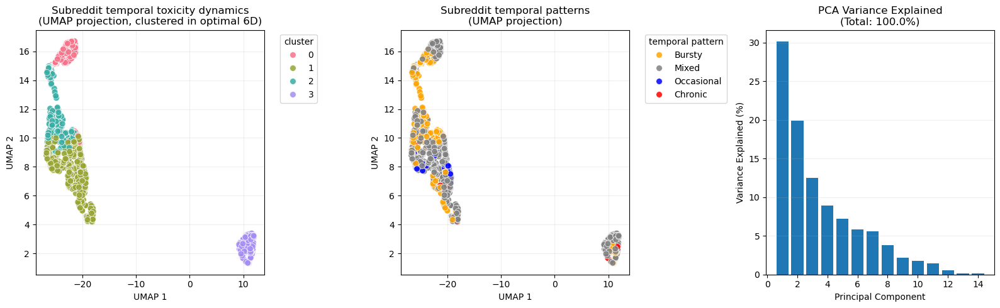

In [35]:
embedding = dimensionality_reduction_2d(X_pca, X_scaled, umap_available, result_df)
plot_cluster_results(result_df, reducer_name, feature_cols, cluster_labels, X_scaled, n_components_optimal)

In [36]:
create_interactive_plotly_visualization(result_df, reducer_name, feature_cols, n_components_optimal)


   Interactive plot created. Hover over points to see details.
  Each point shows: Subreddit name, Cluster interpretation, Temporal pattern, Event counts
  Controls: Scroll to zoom, drag to pan, double-click to reset view

  Interactive plot exported to: subreddit_clustering_interactive.html
  Ready for embedding in Jekyll website


### 2.5.3 Mega-Subreddit Analysis

In [37]:
mega_summary = analyze_mega_subreddits_in_clusters(result_df, n_top=15)


Analyzing 26 mega-subreddits included in clustering...

Top 15 Mega-Subreddits (now clustered):
                 cluster  total_tox_count_raw  src_tox_count_raw  \
subredditdrama         2               8244.0             7550.0   
bestof                 2               3016.0             2828.0   
askreddit              2               2641.0               61.0   
drama                  2               2464.0             2239.0   
circlebroke2           2               1649.0             1599.0   
worldnews              2               1384.0               12.0   
news                   2               1359.0               11.0   
shitpost               2               1284.0             1222.0   
todayilearned          2               1227.0              146.0   
pics                   2               1130.0                2.0   
funny                  2               1122.0               51.0   
shitredditsays         2               1120.0              904.0   
videos             

---
# 1.3 Network Construction and Representation

1. Build temporal network snapshots (monthly/yearly windows as shorter windows seem unreasonable given the data)  
2. Build directed graphs for each time period
3. Compute node edge attributes: degrees, toxicity metrics, network centrality measures, eigenvector centrality
4. Store as adjacency lists or graph objects for analysis

### 1.3.1 Computing overall mean toxicity score

To get an overall idea of whether we can detect clusters of toxic subreddits, we compute the mean toxicity score of the interactions going out of each subreddit, and use the embeddings to map them.

In [38]:
# === Compute mean toxicity for each source subreddit ===
mean_toxicity = (
    interactions_df.groupby("SOURCE_SUBREDDIT")["TOXICITY_SCORE"]
    .mean()
    .rename("mean_toxicity_score")
)

# Sanity check
print(mean_toxicity.head())
print(f"\nTotal subreddits with data: {mean_toxicity.ne(0).sum()} / {len(mean_toxicity)}")

SOURCE_SUBREDDIT
007                 0.000000
07scape             0.015126
07thexpansion       0.025000
098f6bcd4621d373    0.007576
0________0          0.010101
Name: mean_toxicity_score, dtype: float64

Total subreddits with data: 53420 / 55863


### 1.3.2 Mapping most active subreddits mean toxicity score

To obtain a readable and interpretable map (with not too many subreddits), we only keep active subreddits (the ones that have more than 20 outgoing interactions over the time period).
We use UMAP (Uniform Manifold Approximation and Projection) to reduce the dimensionality of the embeddings (300) to a plottable 2D map, to see the proximity between subreddits based on their embedding representations. UMAP is a nonlinear dimensionality reduction technique that preserves both local and global structure in the data, making it well-suited for visualizing complex high-dimensional relationships between subreddits in a 2D space.

In [39]:
# Use utils function to filter active subreddits and get their embeddings
active_subs, filtered_embeddings = filter_active_subreddits(min_interactions=20)

# Reduce filtered embeddings from 3D to 2D
filtered_embeddings_2d = reduce_embeddings_2d(filtered_embeddings)

# Plot embeddings with mean toxicity
plot_static_embeddings_with_toxicity(filtered_embeddings_2d, mean_toxicity)

/opt/miniconda3/envs/ada/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



NameError: name 'plot_static_embeddings_with_toxicity' is not defined

We can already see that some areas have a higher proportion of subreddits with a moderately high mean toxicity score. 
This observation is very broad since it only considers the mean toxicity over the whole period (2.5 years): communities should be easier to observe over a smaller time period, if selected correctly.

### 1.3.3 Monthly evolution of toxicity score

We check whether we can decompose the data into monthly time series by taking advantage of the 'TIMESTAMP' column, still with the most active subreddits, and plot them using an animated UMAP. 
We compute the monthly mean outgoing toxicity score of each subreddit to see their evolution with time.

In [ ]:
ani_monthly = animate_evolution(active_subs, filtered_embeddings, freq='M')
HTML(ani_monthly.to_jshtml())

/Users/cyprien/Desktop/ada-2025-project-adastra/src/utils/network_utils.py:110: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .groupby([pd.Grouper(key='TIMESTAMP', freq=freq), 'SOURCE_SUBREDDIT'])


This animation shows fluctuating toxicity scores for most subreddits, but also clusters who keep mostly toxic interactions throughout the whole time period (such as at the bottom left of the main island).

### 1.3.4 Weekly evolution of toxicity score

To later  be able to investigate cascades of toxicity with more precision, we try visualizing weekly evolution of toxicity scores

In [ ]:
ani_weekly = animate_evolution(active_subs, filtered_embeddings, freq='W')
HTML(ani_weekly.to_jshtml())

Animation size has reached 21200084 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


The result is too heavy to be displayed entirely but shows that we are able to study weekly fluctuations of toxicity of subreddits within a certain time window (to be later determined for cascade analysis).

---
# Phase 2: Outbreak Detection and Analysis (started, to finish after P2)

## 2.1 Community Exploration and Structure Analysis
- Detect subreddit clusters (who interacts with whom?)
- Characterize each community's baseline behavior
- Track community changes over time

### 2.1.1 Using the Louvain algorithm

The Louvain algorithm is a community detection method that groups nodes in a network into clusters (communities) by maximizing modularity, a measure of how densely connected nodes are within communities compared to between them. In our case, we apply the Louvain algorithm to the toxic interaction graph, where nodes represent subreddits and weighted edges represent the number of toxic interactions between them. This allows us to identify clusters of subreddits that frequently exchange toxic messages, revealing potential toxic communities.

Graph built: 9752 nodes, 32224 toxic edges
Detected 1134 communities.
Detected 98 toxic communities.
    COMMUNITY_ID  SIZE
0             18     2
1             29     2
2             30     2
3             35     1
4             39     2
..           ...   ...
93          1111     1
94          1113     2
95          1121     2
96          1125     2
97          1128     2

[98 rows x 2 columns]
Biggest highly toxic community ID: 717
Number of subreddits in this community: 8


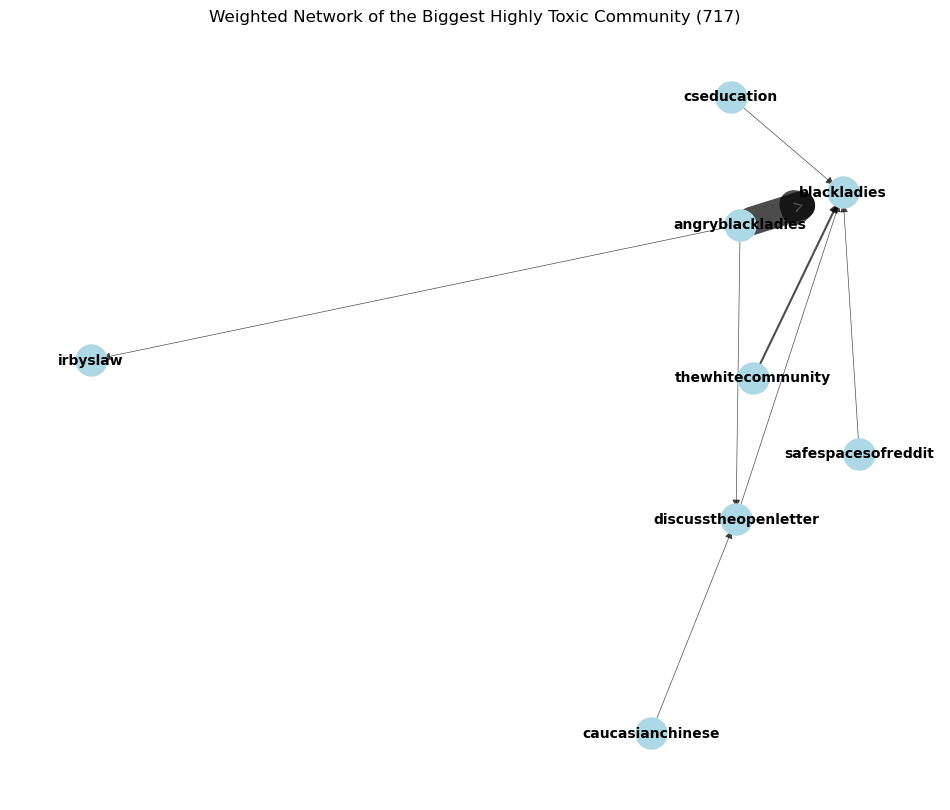

In [ ]:
# Only select toxic interactions to build the graph to detect toxic communities
toxic_df = interactions_df[interactions_df["TOXICITY_CAT"] == 1]  # keep only toxic interactions

# Find Louvain communities from toxic interactions and their number of interactions
community_df, toxic_interactions = louvain_communities(toxic_df)

# We consider communities with more than 30% toxic interactions as toxic
toxicity_threshold = 0.3

# Find toxic communities
community_df = get_toxic_communities(community_df, toxicity_threshold)

# Plot the biggest toxic community network
plot_biggest_toxic_community_network(community_df, toxic_interactions)

We observe that the Louvain algorithm mostly finds very small communities (1 or 2 subreddits). 
This is due to the fact that when using the full time period as we did here, toxic interactions are sparse and scattered across time, leading the Louvain algorithm to detect many small, isolated communities. By focusing on a shorter, well-chosen period where toxicity peaks (to be determined later), interactions are denser and more connected, making it easier to identify larger, more cohesive toxic communities.

## 2.2 Outbreak identification and Characterization
- **Detect outbreaks**: When toxicity suddenly spikes
- **Find origins (Patient-0)**: Which subreddit started it?
- **Measure impact**: How big did the outbreak get?


### 2.2.1 Data Focusing tool

In order to identify the patient 0, we first construct a tool capable of focusing on a time window and on links which contain a specific keyword. This allows us to dig into a more relevant part of the data, and therefore identify more easily trends in a given context. 

We highlight that this method is meant to help faster identification of trends, and that a more rigorous causal analysis will be conducted later on. This is important as this tool may focus too much on parts of the data, and thus eliminate precursors without eliminating their effect. In instance, the actual patient zero subreddit or community might not contain the chosen given in its name, leaving the possibility of having it as a precursor behind. The possibility of having the keyword in a subreddit name with no link is also possible (see example with 'nba', we get 'greeNBAypackers' as a related subreddit).

In [ ]:
# Subreddit keyword to focus on
KEYWORD = "nba"

# Time Window to consider
# TIME_WINDOW = [date(2016, 6, 1), date(2017, 2, 1)] # TRUMP
TIME_WINDOW = [date(2015, 6, 1), date(2015, 8, 1)] # NBA

# Extract focused dadaframe
focused_df = extract_focused_df(interactions_df, KEYWORD, TIME_WINDOW)
focused_df.head(10)

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,...,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER,TYPE,LINK_SENTIMENT_ADJUST,TOXICITY_SCORE,TOXICITY_CAT,year_month,TOXICITY_SCORE_ROLLZ
293374,bestofrabsho,nba,37kkwhs,2015-06-01 06:52:48,1,46.0,41.0,0.760870,0.000000,0.217391,...,0.0,0.000000,0.0,0.0,title,0.00,0.010943,0,2015-06-01,-0.229211
293472,sneakers,nbamarketplace,383eris,2015-06-01 09:53:24,1,84.0,73.0,0.785714,0.000000,0.297619,...,0.0,0.000000,0.0,0.0,title,0.00,0.024784,0,2015-06-01,0.371469
293914,retiredusername,nba,38l1n6s,2015-06-01 21:03:45,1,34.0,31.0,0.794118,0.000000,0.147059,...,0.0,0.000000,0.0,0.0,title,0.00,0.005051,0,2015-06-01,-0.485011
294707,chibears,greenbaypackers,38bikys,2015-06-02 21:28:28,1,7001.0,6553.0,0.611341,0.123982,0.086273,...,0.0,0.000991,0.0,0.0,body,0.00,-0.005694,0,2015-06-01,-0.951057
294759,badeconomics,nba,38bxeis,2015-06-02 23:24:27,1,41.0,36.0,0.804878,0.000000,0.170732,...,0.0,0.000000,0.0,0.0,title,0.00,0.008658,0,2015-06-01,-0.328522
295010,nbacirclejerk,nbastreams,38e048s,2015-06-03 10:26:55,1,36.0,29.0,0.722222,0.000000,0.361111,...,0.0,0.000000,0.0,0.0,title,0.00,0.014731,0,2015-06-01,-0.065217
295354,seahawks,greenbaypackers,38fwkts,2015-06-03 17:47:04,1,4276.0,4117.0,0.654584,0.098223,0.047942,...,0.0,0.000000,0.0,0.0,body,0.00,-0.004901,0,2015-06-01,-0.916776
295458,subredditdrama,nba,38gw77,2015-06-03 21:00:00,-1,106.0,90.0,0.811321,0.000000,0.056604,...,0.0,0.000000,0.0,0.0,title,0.25,0.047456,1,2015-06-01,1.354760
295904,warriors,nba,38k6hc,2015-06-04 13:28:40,-1,921.0,798.0,0.741585,0.017372,0.041260,...,0.0,0.006289,0.0,0.0,body,0.25,0.026492,1,2015-06-01,0.445309
296497,nbacirclejerk,clevelandcavs,38okdos,2015-06-05 09:38:20,1,17.0,17.0,0.823529,0.000000,0.823529,...,0.0,0.000000,0.0,0.0,title,0.00,0.000000,0,2015-06-01,-0.704116


In this example we focus on the NBA keyword and over the course of two months from June 2015 to August 2015. For further information about how the extract_focused_df() function works, please refer to the associated 'identify_patient_zero_module.py' file. Note that the focused_df preserves the order of the given dataframe in entry, time in our case.

### 2.2.2 Analysis of specific subreddits interactions over a given time period
#### Number of daily interactions across each subreddit
We start by conducting a temporal analysis of all interactions, as source or as target. This allows us to identify interaction outbreaks, which will be further analyzed to see if they are positive, negative and/or toxic events.

There are 111 different subreddits acting as source.
There are 61 different subreddits acting as target.


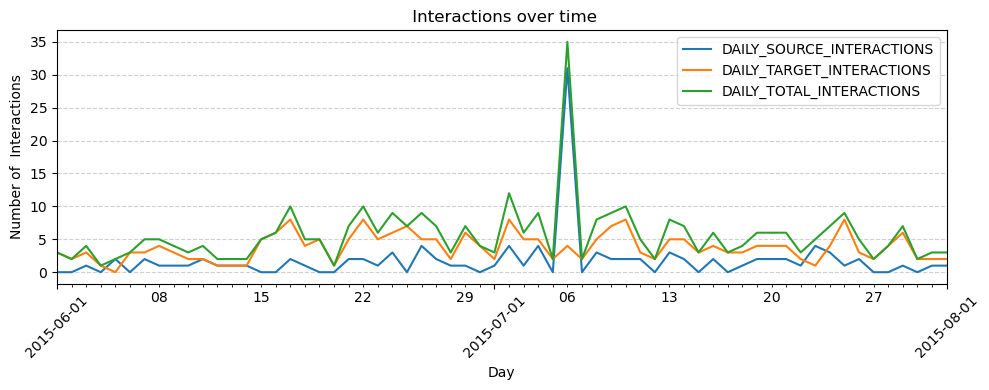

In [ ]:
print("There are", len(focused_df["SOURCE_SUBREDDIT"].unique()), "different subreddits acting as source.")
print("There are", len(focused_df["TARGET_SUBREDDIT"].unique()), "different subreddits acting as target.")

# Count the number of daily interactions across all considered subreddits
daily_interaction_df = construct_daily_interaction_df(focused_df, KEYWORD, TIME_WINDOW)

plot_daily_interactions(daily_interaction_df[["DAILY_SOURCE_INTERACTIONS",
                                              "DAILY_TARGET_INTERACTIONS",
                                              "DAILY_TOTAL_INTERACTIONS"]])

We can see that a clear outbreak appears at the beginning of July 2015. We can also see that overall there are more targeted subreddits than source (a smaller amount of subreddits target more other subreddits). But during the outbreak, the number of source subreddits explodes, indicating a lot more different subreddits linked to the same (small) amount of target subreddits. This could be a toxic wave coming from various different communities towards a particular subreddit.

#### Number of interactions (as source and target) for each subreddit 

To further analyze which subreddits are potential victims and prosecutors, we show the amount of interactions (as source and as target) for the 8 most interactive subreddits.

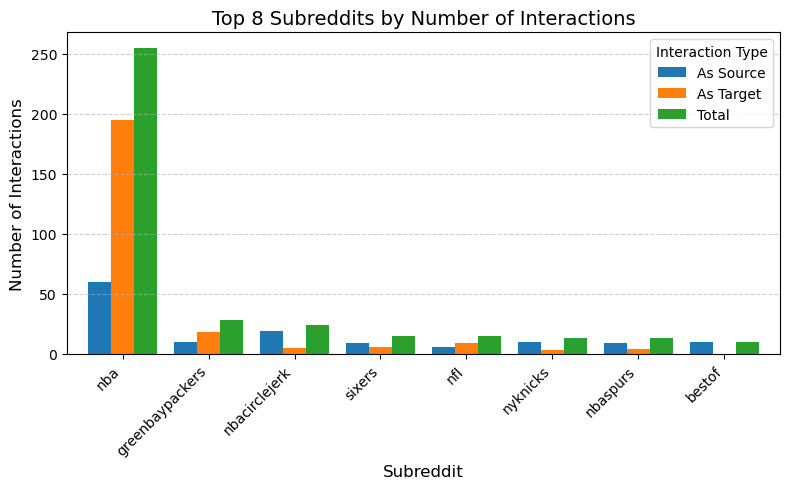

In [ ]:
# Count the number of interaction as source and as target for each subreddit
sr_interaction_count_df = construct_interaction_count_df(focused_df)

# Choose the number of subreddits to plot
NB_TO_PLOT = 8

plot_top_interactors(sr_interaction_count_df,
                     x_col = "SUBREDDIT",
                     y_cols = ["SOURCE_INTERACTIONS", "TARGET_INTERACTIONS", "TOTAL_INTERACTIONS"],
                     legend = ["As Source", "As Target", "Total"],
                     x_ticklabels=sr_interaction_count_df.head(NB_TO_PLOT)["SUBREDDIT"],
                     plot_top = NB_TO_PLOT)

A clear trend of links towards the 'nba' subreddit shows up, and some others like the 'nbacirclejerk' appears as one of the most targeting subreddit. Although, the balance between subreddits is not equitable and therefore if any toxic outbreak were to be happening, this would mean many attackers are implied rather than a specific subreddit. This makes the analysis more complicated, as we have to analyze the evolution interactions for each small subreddit separately. This is because we need to see if it is indeed a change in their behaviour or a recurrent interaction between the target and the source. 

### Number of negative daily interactions across each subreddit 

We now study the interactions themselves to see if they are negative and/or toxic based on as many criteria as wanted. Here, we take:
- 'LINK_SENTIMENT' == -1,
- 'TOXICITY_CAT' == 1

More criteria could be explored (and will in P3), like the 'TOXICITY_SCORE_ROLLZ', giving a broader view on the negative interactions. For the sake of simplicity, we will not consider more complete metrics, as the goal here is to present a tool made to roughly identify outbreaks and their nature (toxic or not). This is a preliminary study meant to go deeper in the causal analysis part.

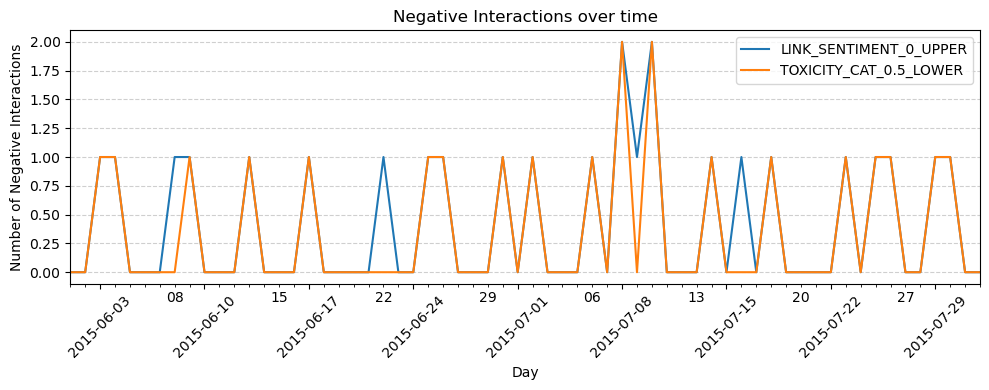

,LINK_SENTIMENT_0_UPPER,TOXICITY_CAT_0.5_LOWER
DAY,,
2015-06-01,0,0
2015-06-02,0,0
2015-06-03,1,1
2015-06-04,1,1
2015-06-05,0,0
...,...,...
2015-07-28,0,0
2015-07-29,1,1
2015-07-30,1,1


In [ ]:
# Count the number of negative daily interactions across all considered subreddits
CRITERION = ["LINK_SENTIMENT",
             "TOXICITY_CAT"
             ]
THRESHOLDS = [0,
              0.5
              ]
UPPER = [True,
         False
        ]
daily_neg_interaction_df = construct_neg_interaction_df(focused_df, 
                                                        time_window=TIME_WINDOW, 
                                                        criteria=CRITERION, 
                                                        threshold=THRESHOLDS, 
                                                        upper=UPPER,
                                                        groupby_type="DAY")


plot_daily_interactions(daily_neg_interaction_df, day_interval = 7, specifier = "Negative")

# Show dataframe for further investigation
daily_neg_interaction_df

It appears that during the outbreak, very few are actually detected (1 over 30 the same day, 2 over 30 the next day) as negative from LINK_SENTIMENT. Same goes for links detected as toxic (even less, which is expected since a toxic link is usually negative but a negative link is not necessarily toxic), which indicates a low amount of negativity/toxicity during the outbreak. As expected, LINK_SENTIMENT and TOXIC_CAT show very similar trends, and their relevance against each other will be analyzed and discussed later on (P3). 

In this example, we would tend to say this is not a major negative outbreak, and that these results are non-conclusive. This could be an outbreak with regular amount of toxicity, or simply a non-negative outbreak. Note again that this should and will be further analyzed to quantify the regular amount of toxicity and that relevance of criteria should be investigated (causal analysis in P3).

#### Number of negative aggregated interactions for each subreddit

Finally, we add a plot showing the number of negative interactions for each subreddit which allow us to highlight which subreddit is associated with negative links.

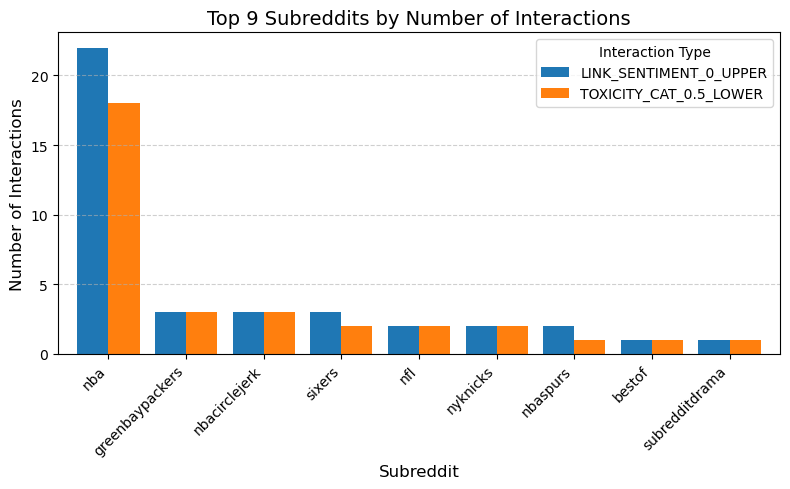

In [ ]:
# Count the number of negative interactions for each considered subreddit

# Compute negative interactions as source
sr_neg_source_interaction_df = construct_neg_interaction_df(focused_df, 
                                                        time_window=TIME_WINDOW, 
                                                        criteria=CRITERION, 
                                                        threshold=THRESHOLDS, 
                                                        upper=UPPER,
                                                        groupby_type="SOURCE_SUBREDDIT")

# Compute negative interactions as target
sr_neg_target_interaction_df = construct_neg_interaction_df(focused_df, 
                                                        time_window=TIME_WINDOW, 
                                                        criteria=CRITERION, 
                                                        threshold=THRESHOLDS, 
                                                        upper=UPPER,
                                                        groupby_type="TARGET_SUBREDDIT")

# Add interactions and sort them by total
sr_neg_interaction_df = smart_df_add(sr_neg_source_interaction_df, sr_neg_target_interaction_df)
sr_neg_interaction_df["TOTAL_NEGATIVE_INTERACTIONS"] = sr_neg_interaction_df.sum(axis=1)
sr_neg_interaction_df = sr_neg_interaction_df.sort_values(by="TOTAL_NEGATIVE_INTERACTIONS", ascending=False)

# Choose the number of subreddits to plot
NB_TO_PLOT = 9

plot_top_interactors(sr_neg_interaction_df,
                     x_col = None,
                     y_cols = sr_neg_interaction_df.columns[:-1],
                     legend = sr_neg_interaction_df.columns,
                     x_ticklabels = sr_interaction_count_df.head(NB_TO_PLOT)["SUBREDDIT"],
                     plot_top = NB_TO_PLOT)

Again, the 'nba' subreddit stands out which makes sense as it was the most interactive during this period. We can see that the total amount of negative interactions goes up to roughly 22 over 250 total interactions based on LINK_SENTIMENT, and even less using our TOXICITY_CAT metric. As explained above, habitual toxic interaction ratio and relevance of each criterion should be further investigated and motivated. However, this does not indicate a highly toxic outbreak.

We therefore cannot assess if it was a negative outbreak for the 'nba' subreddit or not, based on the current results. This is still a good example of how we aim to find potential patient-0, as a first step in the whole process. We emphasize the complexity of this task which still needs deeper analysis (see causal analysis next), and we are aware that a more detailed exploration is needed (pursued in P3).

### 2.2.3 Causal Analysis (P3)

This allows us to perform a more trustful study based on the prior beliefs obtained in the previous section. This includes assessing relevance of criteria and thresholds and global toxic trends of each subreddit in this context among others.

---
# Phase 3: Propagation and Diffusion Analysis (after P2)

## 3.1 Cascade Tracing and Flow Dynamics
- **Find chains**: A→B→C toxic spreading patterns
- **Analyze mutations**: How toxicity changes as it spreads
- **Model contagion**: What makes toxicity spread?

## 3.2 Immunity and Containment Effects
- **Positive alliances**: Do friendly connections protect communities?
- **Resistance factors**: What makes communities immune?

---

# Phase 4: Lifecycle and Evolution Study (after P2)


## 4.1 Detection of Cycles and Key Events
- **Periodicity**: Does toxicity follow seasonal patterns? (Fourier analysis)
- **Event correlation**: Do real-world events trigger spikes?

## 4.2 Evolutionary tracking over time
- **Classify trajectories**: How do toxic communities evolve?: Is there a gradual radicalization? Or sudden outbreaks? Do we observe chronic toxicity?
- **Early warning**: Try to predict which communities will become toxic

---
# Phase 5: Validation and Synthesis of Results (Conclusion)



## 5.1 Create Visualizations
We could create various visualizations to effectively communicate our findings. Examples such as :  Animated networks showing toxicity spread, Epidemic curves (like flu charts), etc.


## 5.2 Final Interpretation and Conclusions